In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("/content/cleaned_adult_data.csv")

# Display the dataset size
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first five rows
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (30139, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
# Summary statistics for numerical columns
print("Descriptive Statistics")
display(df.describe())

# Summary of categorical columns
print("Categorical Data Summary")
display(df.describe(include="object"))

Descriptive Statistics


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,30139.000000,3.013900e+04,30139.000000,30139.000000,30139.000000,30139.000000
mean,38.441720,1.897950e+05,10.122532,1092.841202,88.439928,40.934703
std,13.131426,1.056586e+05,2.548738,7409.110596,404.445239,11.978753
min,17.000000,1.376900e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.176275e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.784170e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.376045e+05,13.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


Categorical Data Summary


,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
count,30139,30139,30139,30139,30139,30139,30139,30139,30139
unique,7,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22264,9834,14059,4034,12457,25912,20366,27487,22633


In [ ]:
# Count observations in each income category
income_counts = df["income"].value_counts()

print("Income category counts:")
display(income_counts)

# Calculate percentages
income_percentages = df["income"].value_counts(normalize=True) * 100

print("Income category percentages:")
display(income_percentages.round(2))

Income category counts:


,count
income,
<=50K,22633
>50K,7506


Income category percentages:


,proportion
income,
<=50K,75.1
>50K,24.9


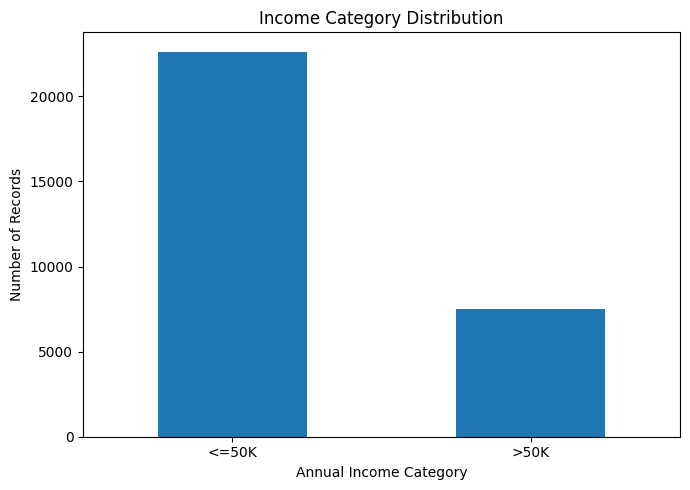

In [ ]:
import matplotlib.pyplot as plt

# Count records in each income category
income_counts = df["income"].value_counts().reindex(
    ["<=50K", ">50K"]
)

# Create the bar graph
plt.figure(figsize=(7, 5))
income_counts.plot(kind="bar")

# Add labels and title
plt.title("Income Category Distribution")
plt.xlabel("Annual Income Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

# Display the graph
plt.tight_layout()
plt.show()

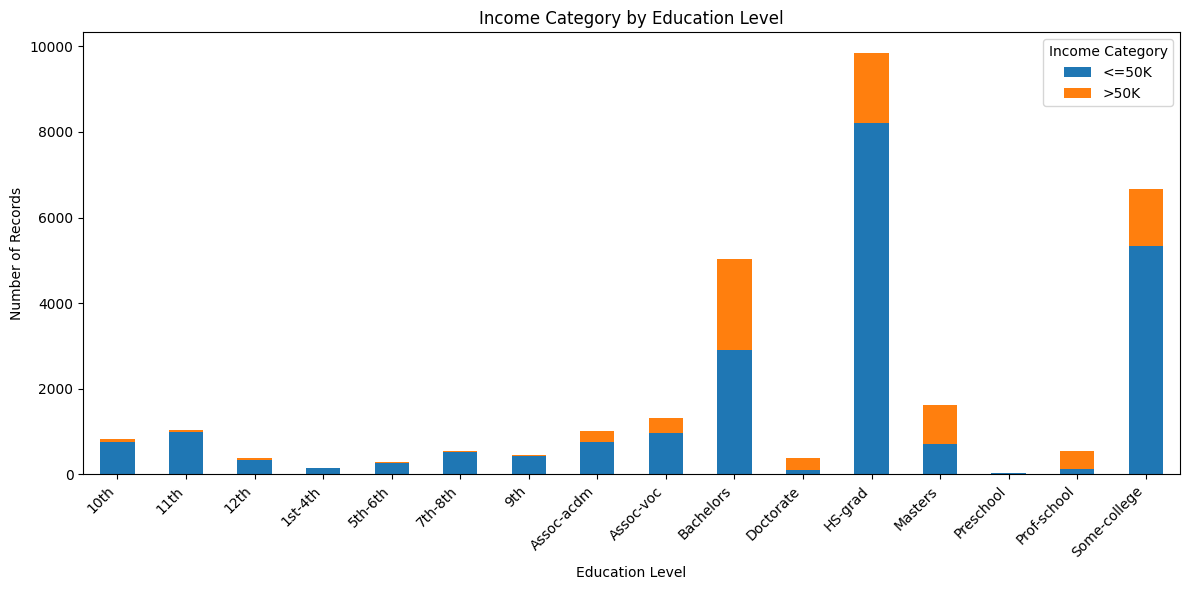

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a table showing education and income
education_income = pd.crosstab(
    df["education"],
    df["income"]
)

# Plot a stacked bar chart
education_income.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

# Add title and labels
plt.title("Income Category by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income Category")
plt.tight_layout()

# Display the graph
plt.show()

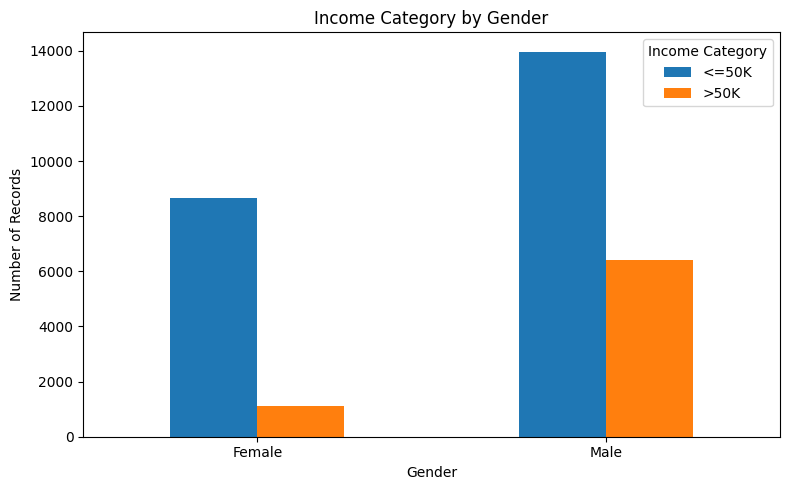

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Count income categories by gender
gender_income = pd.crosstab(
    df["sex"],
    df["income"]
)

# Create a grouped bar chart
gender_income.plot(
    kind="bar",
    figsize=(8, 5)
)

# Add title and labels
plt.title("Income Category by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Income Category")
plt.tight_layout()

# Display the graph
plt.show()

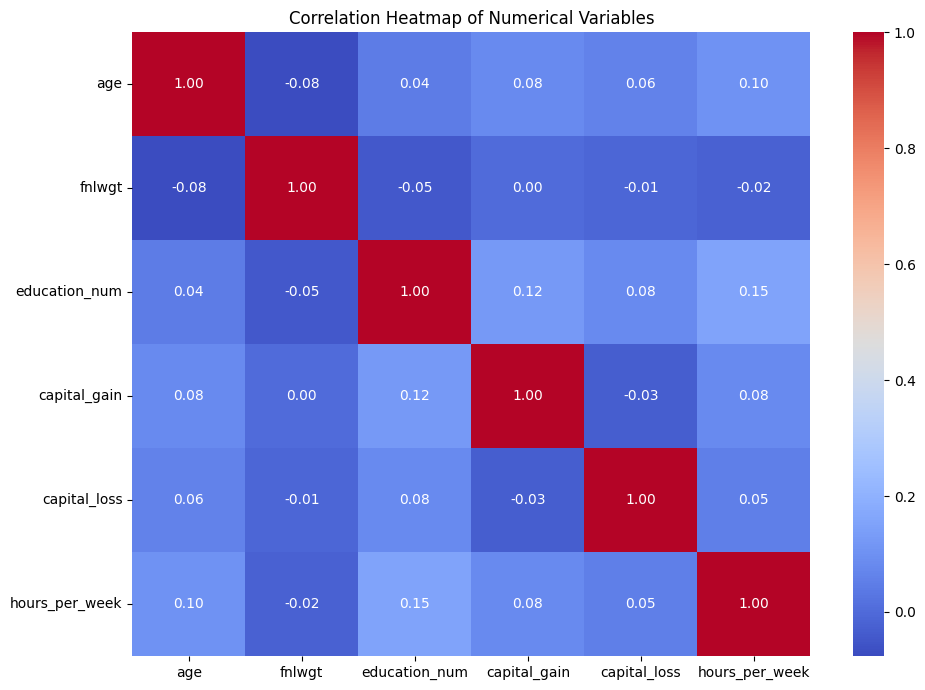

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Create the heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

df = pd.read_csv("/content/cleaned_adult_data.csv")

print("Dataset loaded successfully!")
print("Dataset size:", df.shape)


Dataset loaded successfully!
Dataset size: (30139, 15)


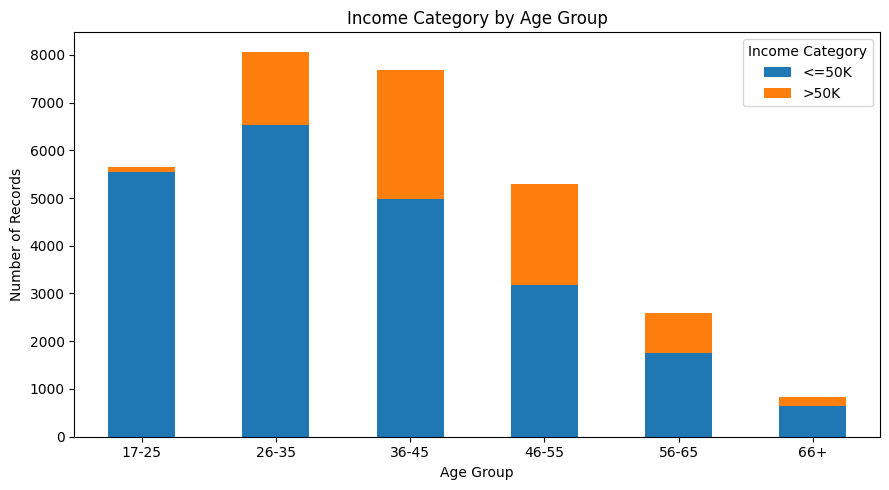

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[16, 25, 35, 45, 55, 65, 100],
    labels=[
        "17-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66+"
    ],
    include_lowest=True
)

# Count income categories in each age group
age_income = pd.crosstab(
    df["age_group"],
    df["income"]
).reindex(columns=["<=50K", ">50K"], fill_value=0)

# Create a stacked bar chart
age_income.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Income Category by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Income Category")
plt.tight_layout()
plt.show()


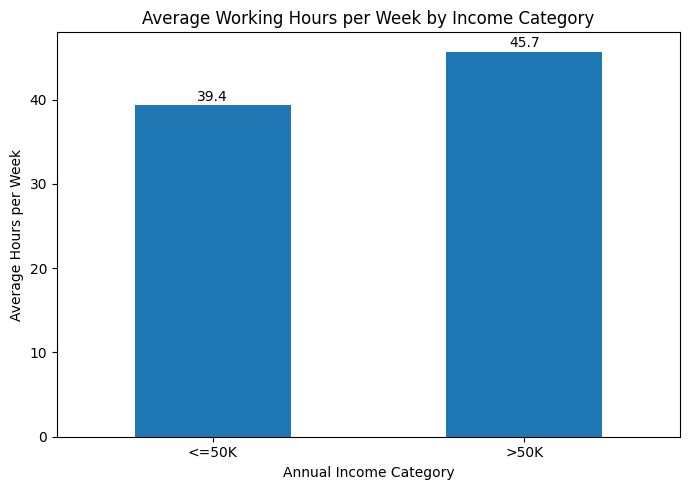

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate average weekly working hours by income category
average_hours = df.groupby("income")["hours_per_week"].mean()
average_hours = average_hours.reindex(["<=50K", ">50K"])

# Create a bar graph
plt.figure(figsize=(7, 5))
average_hours.plot(kind="bar")

# Add title and labels
plt.title("Average Working Hours per Week by Income Category")
plt.xlabel("Annual Income Category")
plt.ylabel("Average Hours per Week")
plt.xticks(rotation=0)

# Display values above the bars
for i, value in enumerate(average_hours):
    plt.text(i, value + 0.5, f"{value:.1f}", ha="center")

plt.tight_layout()
plt.show()

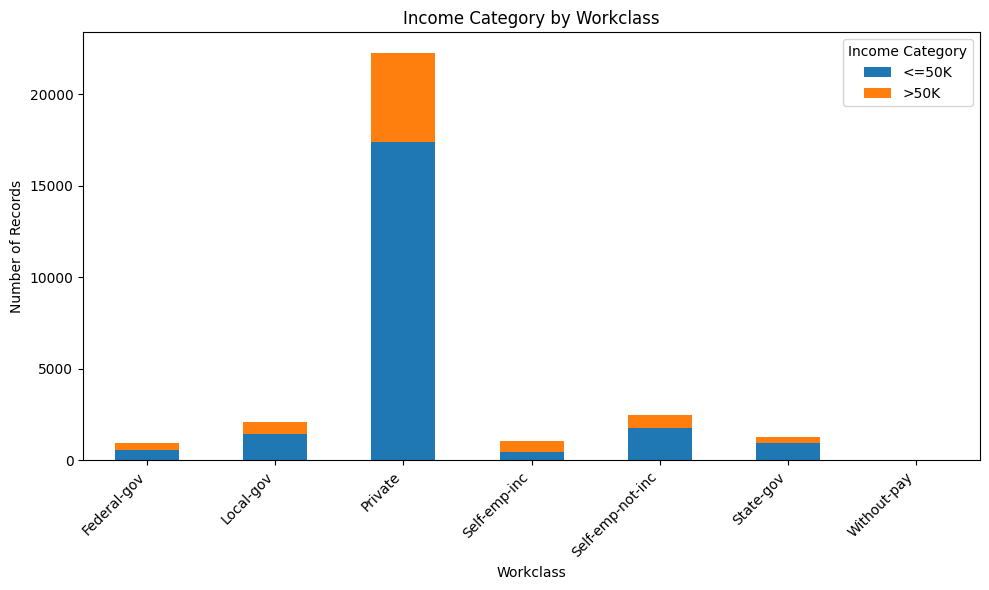

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Count income categories by workclass
workclass_income = pd.crosstab(
    df["workclass"],
    df["income"]
).reindex(columns=["<=50K", ">50K"], fill_value=0)

# Create a stacked bar chart
workclass_income.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

# Add title and labels
plt.title("Income Category by Workclass")
plt.xlabel("Workclass")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income Category")
plt.tight_layout()
plt.show()

## Key Findings — Adult Census Income Analysis

### 1. Dataset Overview
The cleaned Adult Census Income dataset contains **30,139 records and 15 columns**. The data includes demographic characteristics, education, employment, working hours, and annual income categories.

### 2. Income Distribution
Approximately 75.1% of records belong to the income category of $50,000 or less, while 24.9% belong to the category earning more than 50,000 dollars

### 3. Education and Income
The education-level graph shows differences in the number of records across education categories and income groups. These differences should be interpreted alongside the number of people represented in each category.

### 4. Gender and Income
The dataset contains more male records than female records. Both groups include people in the lower- and higher-income categories.

### 5. Age and Income
The age-group graph shows differences in income-category counts across age groups. The 26–35 age group has the largest total number of records in the plotted groups.

### 6. Working Hours and Income
The average working time is approximately 39.4 hours per week for the 50,000 dollars-or-less income group and 45.7 hours per week for the above-50,000 dollars income group

### 7. Workclass and Income
Private-sector workers account for the largest number of records in the dataset. Other workclasses have substantially fewer observations.

### 8. Correlation Analysis
Most correlations between the numerical variables are weak. Education and weekly working hours have a correlation of approximately 0.15, indicating a weak positive linear relationship.

### Conclusion
The exploratory analysis reveals differences in income categories across demographic and employment groups. These are descriptive findings and do not establish causation. Further analysis using proportions and suitable statistical methods would help assess the relationships more carefully.

# TASK 3: DATA VISUALIZATION DASHBOARD

This task focuses on creating clear and meaningful visualizations using Python.

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("/content/cleaned_adult_data.csv")

print("Task 3 dataset loaded successfully!")
print("Dataset shape:", df.shape)


Task 3 dataset loaded successfully!
Dataset shape: (30139, 15)


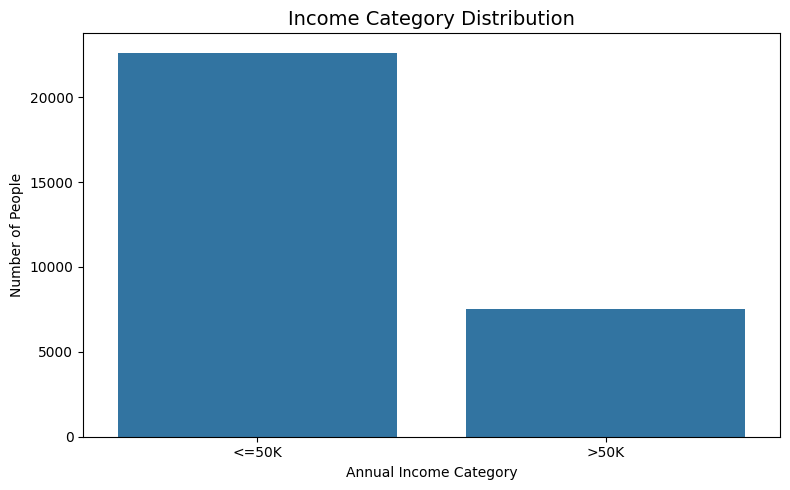

In [4]:

# Graph 1: Income Category Distribution

income_counts = df["income"].value_counts().reindex(["<=50K", ">50K"], fill_value=0)

plt.figure(figsize=(8, 5))
sns.barplot(x=income_counts.index, y=income_counts.values)

plt.title("Income Category Distribution", fontsize=14)
plt.xlabel("Annual Income Category")
plt.ylabel("Number of People")

plt.tight_layout()
plt.show()


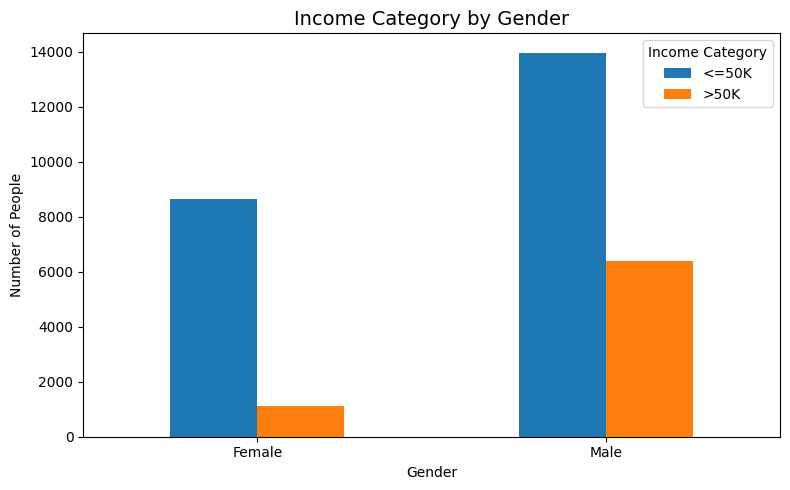

In [5]:

# Graph 2: Income Category by Gender

gender_income = pd.crosstab(df["sex"], df["income"])
gender_income = gender_income.reindex(
    index=["Female", "Male"],
    columns=["<=50K", ">50K"],
    fill_value=0
)

gender_income.plot(kind="bar", figsize=(8, 5))

plt.title("Income Category by Gender", fontsize=14)
plt.xlabel("Gender")
plt.ylabel("Number of People")
plt.xticks(rotation=0)
plt.legend(title="Income Category")
plt.tight_layout()
plt.show()


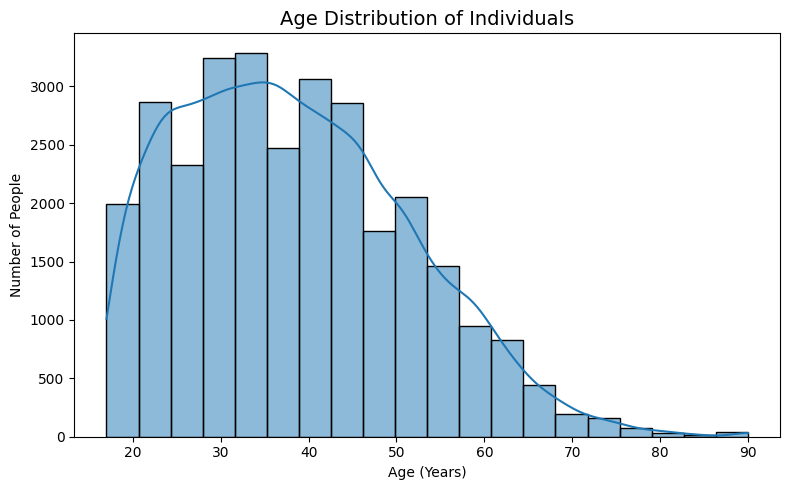

In [6]:

# Task 3 - Graph 3: Age Distribution Histogram

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution of Individuals", fontsize=14)
plt.xlabel("Age (Years)")
plt.ylabel("Number of People")

plt.tight_layout()
plt.show()

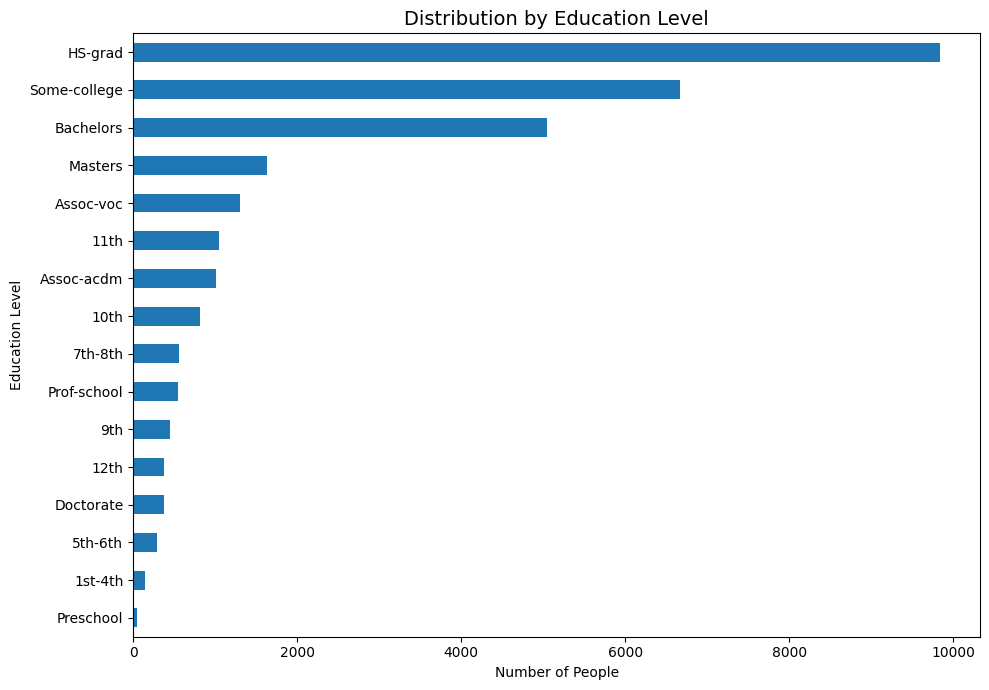

In [7]:

# Task 3 - Graph 4: Education Level Distribution

education_counts = df["education"].value_counts().sort_values()

plt.figure(figsize=(10, 7))

education_counts.plot(kind="barh")

plt.title("Distribution by Education Level", fontsize=14)
plt.xlabel("Number of People")
plt.ylabel("Education Level")

plt.tight_layout()
plt.show()


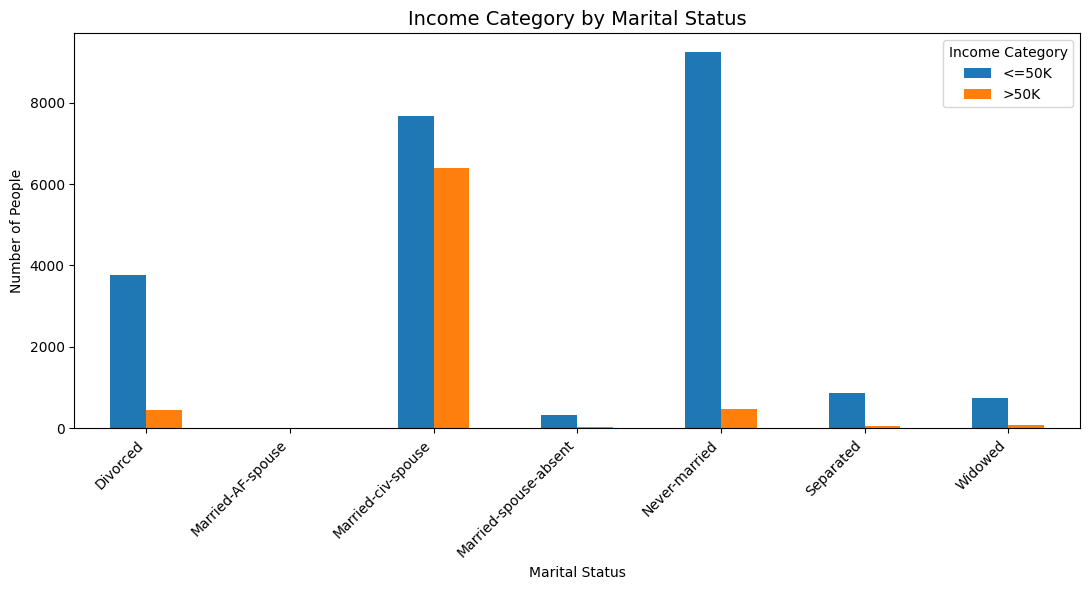

In [8]:

# Task 3 - Graph 5: Income Category by Marital Status

marital_income = pd.crosstab(df["marital_status"], df["income"])
marital_income = marital_income.reindex(
    columns=["<=50K", ">50K"], fill_value=0
)

marital_income.plot(kind="bar", figsize=(11, 6))

plt.title("Income Category by Marital Status", fontsize=14)
plt.xlabel("Marital Status")
plt.ylabel("Number of People")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income Category")
plt.tight_layout()
plt.show()


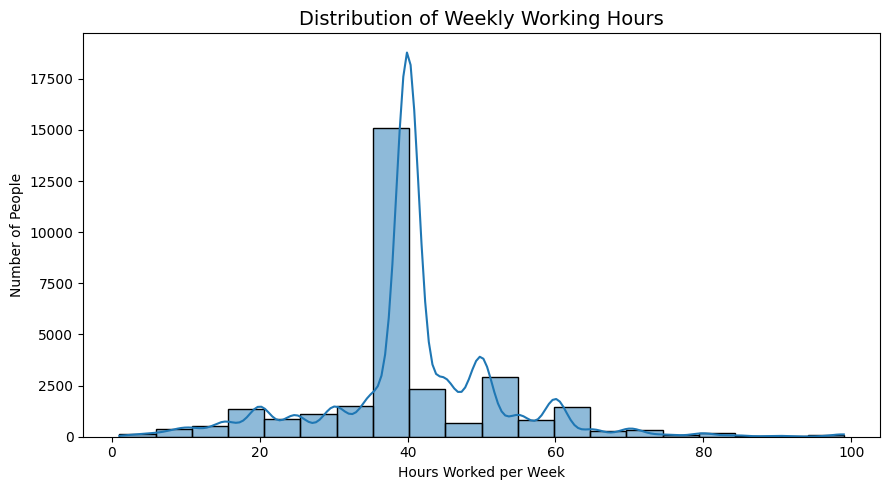

In [9]:

# Task 3 - Graph 6: Weekly Working Hours Distribution

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="hours_per_week", bins=20, kde=True)

plt.title("Distribution of Weekly Working Hours", fontsize=14)
plt.xlabel("Hours Worked per Week")
plt.ylabel("Number of People")

plt.tight_layout()
plt.show()


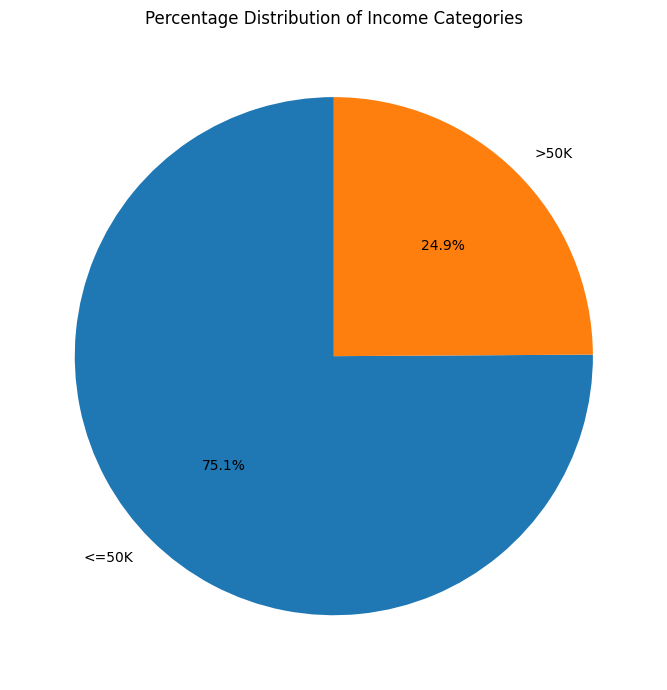

In [10]:

# Task 3 - Graph 7: Income Category Pie Chart

income_counts = df["income"].value_counts().reindex(
    ["<=50K", ">50K"], fill_value=0
)

plt.figure(figsize=(7, 7))

plt.pie(
    income_counts.values,
    labels=income_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Income Categories")
plt.tight_layout()
plt.show()


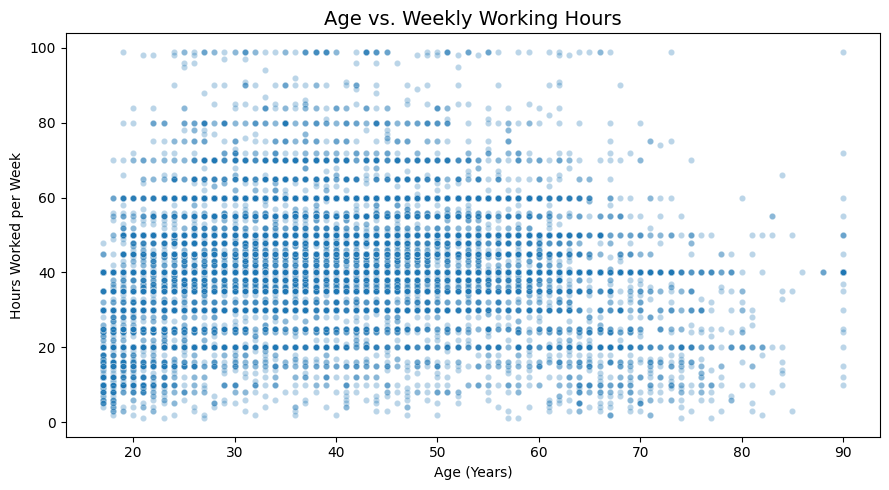

In [11]:

# Task 3 - Graph 8: Age vs. Weekly Working Hours

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="hours_per_week",
    alpha=0.3,
    s=20
)

plt.title("Age vs. Weekly Working Hours", fontsize=14)
plt.xlabel("Age (Years)")
plt.ylabel("Hours Worked per Week")

plt.tight_layout()
plt.show()


# TASK 3: KEY FINDINGS AND CONCLUSION

## Key Findings

1. **Income distribution:** Approximately 75.1% of records belong to the `<=50K` income category, while 24.9% belong to the `>50K` category.

2. **Age distribution:** The dataset contains more records among adults aged approximately 25–45 than among older age groups.

3. **Education:** High-school graduates (HS-grad) form the largest education category, followed by people with some college education and bachelor's degrees.

4. **Marital status:** The number of records and their income-category distribution vary across marital-status groups.

5. **Working hours:** Weekly working hours are concentrated around 40 hours, although some records show considerably fewer or more hours.

6. **Age and working hours:** The scatter plot shows variation in working hours across ages, without establishing a causal relationship.

## Conclusion

This project uses Python, Pandas, Matplotlib, and Seaborn to visualize the cleaned Adult Census Income dataset. Bar charts, histograms, a pie chart, and a scatter plot were used to examine income distribution and its patterns across demographic and employment characteristics.

The results are descriptive and do not establish that any characteristic causes a particular income level. The findings apply to the cleaned dataset and should not automatically be generalized to the entire population.

## Tools Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab